# Import packages

In [ ]:
import json
from pathlib import Path

import pandas as pd

# Read data

## Activity and accompany inference data

In [27]:
df_act_acc = pd.read_csv('../../data/YouTube/YouTube_inferenced.csv')
df_act = df_act_acc[['video_id', 'activity']]
df_acc = df_act_acc[['video_id', 'accompany_type']].drop_duplicates('video_id').reset_index(drop=True)

## Gender and age inference data

In [2]:
def find_gender_age_dir(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for base in candidates:
        candidate = base / "data" / "YouTube" / "gender_age_output"
        if candidate.exists():
            return candidate
    raise FileNotFoundError("Could not find data/YouTube/gender_age_output from the current working directory.")


gender_age_dir = find_gender_age_dir()
json_files = sorted(gender_age_dir.glob("*.json"))

if not json_files:
    raise FileNotFoundError(f"No JSON files found in {gender_age_dir}")

video_rows = []
shot_rows = []
face_rows = []

for json_file in json_files:
    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    video_id = data["video_id"]
    video_rows.append(
        {
            "video_id": video_id,
            "total_shots_with_persons": data.get("total_shots_with_persons", 0),
            "total_faces_detected": data.get("total_faces_detected", 0),
            "detector_backend": data.get("inference_metadata", {}).get("detector_backend"),
        }
    )

    for shot in data.get("shots", []):
        faces = shot.get("faces", [])
        shot_rows.append(
            {
                "video_id": video_id,
                "shot_id": shot.get("shot_id"),
                "scene_tag": shot.get("scene_tag"),
                "has_face": shot.get("has_face", False),
                "face_count": len(faces),
            }
        )

        for face in faces:
            face_rows.append(
                {
                    "video_id": video_id,
                    "shot_id": shot.get("shot_id"),
                    "scene_tag": shot.get("scene_tag"),
                    "frame": face.get("frame"),
                    "face_index": face.get("face_index"),
                    "age": pd.to_numeric(face.get("age"), errors="coerce"),
                    "gender": face.get("gender"),
                    "gender_confidence": pd.to_numeric(face.get("gender_confidence"), errors="coerce"),
                }
            )

df_video = pd.DataFrame(video_rows)
df_shot = pd.DataFrame(shot_rows)
df_face = pd.DataFrame(face_rows)

print(f"Read {len(json_files)} inferred gender/age file(s) from: {gender_age_dir}")
print(f"Videos: {len(df_video)}")
print(f"Shots: {len(df_shot)}")
print(f"Faces: {len(df_face)}")

df_face.head()

Read 4629 inferred gender/age file(s) from: /scratch/project_2006782/leyixu/LVVI3_YouTube/data/YouTube/gender_age_output
Videos: 4629
Shots: 103801
Faces: 60343


,video_id,shot_id,scene_tag,frame,face_index,age,gender,gender_confidence
0,-0-sLChwN2w,shot_1,Scene-001,-0-sLChwN2w-Scene-001-02.jpg,0,28,Man,98.992798
1,-0-sLChwN2w,shot_7,Scene-007,-0-sLChwN2w-Scene-007-02.jpg,0,30,Man,59.181374
2,-0-sLChwN2w,shot_12,Scene-012,-0-sLChwN2w-Scene-012-02.jpg,0,24,Man,94.660469
3,-0-sLChwN2w,shot_13,Scene-013,-0-sLChwN2w-Scene-013-02.jpg,0,30,Woman,75.286774
4,-0-sLChwN2w,shot_15,Scene-015,-0-sLChwN2w-Scene-015-01.jpg,0,27,Woman,73.752937


In [7]:
df_face = df_face[df_face['gender_confidence']>=90]
df_face_group = df_face.groupby(['video_id', 'face_index', 'gender'], as_index=False).mean(numeric_only=True)
df_face_group

,video_id,face_index,gender,age,gender_confidence
0,-0-sLChwN2w,0,Man,28.777778,96.087788
1,-0YdxCHEmjg,0,Man,39.000000,91.798630
2,-0YdxCHEmjg,1,Woman,31.000000,93.066879
3,-3U3egVFHmQ,0,Man,29.000000,95.910166
4,-3U3egVFHmQ,1,Man,29.000000,90.531113
...,...,...,...,...,...
4008,vl9mYvHAmo8,0,Woman,30.000000,94.806564
4009,vnDV7rExaq4,0,Man,33.750000,93.538774
4010,vnDV7rExaq4,0,Woman,35.000000,97.523022
4011,voxncBfHc4E,0,Man,26.000000,97.024139


In [29]:
df_face = df_face_group.loc[
    df_face_group.groupby(['video_id', 'face_index'])['gender_confidence'].idxmax()
].reset_index(drop=True)

df_face

,video_id,face_index,gender,age,gender_confidence
0,-0-sLChwN2w,0,Man,28.777778,96.087788
1,-0YdxCHEmjg,0,Man,39.000000,91.798630
2,-0YdxCHEmjg,1,Woman,31.000000,93.066879
3,-3U3egVFHmQ,0,Man,29.000000,95.910166
4,-3U3egVFHmQ,1,Man,29.000000,90.531113
...,...,...,...,...,...
3430,vk8zU4dNkxQ,0,Man,50.000000,99.992538
3431,vl9mYvHAmo8,0,Woman,30.000000,94.806564
3432,vnDV7rExaq4,0,Woman,35.000000,97.523022
3433,voxncBfHc4E,0,Man,26.000000,97.024139


In [32]:
len(df_face.video_id.unique().tolist())

2090

In [33]:
df = pd.merge(df_acc, df_face, on='video_id', how='left')
df.head(50)

,video_id,accompany_type,face_index,gender,age,gender_confidence
0,-0-sLChwN2w,NaN,0.0,Man,28.777778,96.087788
1,-0G5ELjo5Tw,NaN,NaN,NaN,NaN,NaN
2,-0YdxCHEmjg,With friends,0.0,Man,39.000000,91.798630
3,-0YdxCHEmjg,With friends,1.0,Woman,31.000000,93.066879
4,-2i-J9upMhI,NaN,NaN,NaN,NaN,NaN
5,-35TIalGT7w,Alone,NaN,NaN,NaN,NaN
6,-3U3egVFHmQ,"With club, association",0.0,Man,29.000000,95.910166
7,-3U3egVFHmQ,"With club, association",1.0,Man,29.000000,90.531113
8,-49NSI3oFqc,NaN,0.0,Man,33.250000,95.631269
9,-5kErY-kzCc,NaN,0.0,Man,43.437500,94.544381


In [31]:
df_face[df_face['video_id']=='_zR8UTFSE3c']

,video_id,face_index,gender,age,gender_confidence


# Data analysis

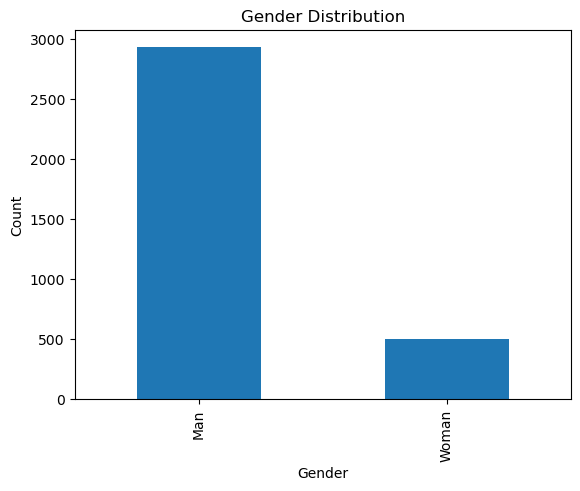

In [12]:
import matplotlib.pyplot as plt

df_result['gender'].value_counts().plot(kind='bar')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Gender Distribution')
plt.show()

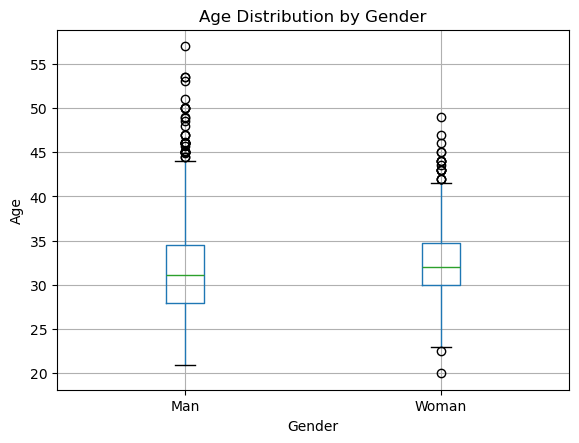

In [13]:
df_result.boxplot(column='age', by='gender')
plt.title('Age Distribution by Gender')
plt.suptitle('')  # removes default extra title
plt.xlabel('Gender')
plt.ylabel('Age')
plt.show()